<a href="https://colab.research.google.com/github/atomychhh/classification_CIC_MalMem2022/blob/main/lab_classification_CIC_MalMem2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/YOUR_USERNAME/YOUR_REPO/blob/main/lab_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота: Класифікація даних кібербезпеки (CIC-MalMem-2022)

**Мета роботи:** ознайомитися з базовим workflow задачі класифікації — від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки Scikit-learn.

**Датасет:** [CIC-MalMem-2022 (Malware Memory Analysis)](https://www.kaggle.com/datasets/luccagodoy/obfuscated-malware-memory-2022-cic) — датасет, створений дослідниками Canadian Institute for Cybersecurity (CIC), University of New Brunswick. Містить 58 596 записів аналізу дампів пам'яті процесів (55 числових ознак, отриманих інструментом VolMemLyzer), збалансовано розділених на Benign (нормальна поведінка системи) та Malware (Ransomware, Spyware, Trojan Horse).

**Тематика:** кібербезпека — задача малваре-детекції (malware classification) за поведінковими ознаками пам'яті процесів.


## 1. Завантаження та первинний аналіз даних

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

sns.set_style("whitegrid")
RANDOM_STATE = 42


In [ ]:
# Датасет CIC-MalMem-2022, взятий з офіційного джерела CIC (UNB) / Kaggle
url = "https://raw.githubusercontent.com/Adnane017/Detecting_new_obfuscated_malware_variants/main/Obfuscated-MalMem2022.csv"
df = pd.read_csv(url)

print("Розмір датасета (рядки, колонки):", df.shape)


Розмір датасета (рядки, колонки): (58596, 57)


In [ ]:
# Назви колонок
print(df.columns.tolist())


['Category', 'pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles', 'psxview.not_in_session', 'psxview.not_in_deskthrd', 'psxview.not_in_pslist_false_avg', 'psxview.not_in_eprocess_pool_false_avg', 'psxview.not_in_ethread_pool_false_avg'

In [ ]:
df.head()


,Category,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,...,svcscan.kernel_drivers,svcscan.fs_drivers,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric,Class
0,Benign,45,17,10.555556,0,202.844444,1694,38.500000,9129,212.302326,...,221,26,24,116,0,121,87,0,8,Benign
1,Benign,47,19,11.531915,0,242.234043,2074,44.127660,11385,242.234043,...,222,26,24,118,0,122,87,0,8,Benign
2,Benign,40,14,14.725000,0,288.225000,1932,48.300000,11529,288.225000,...,222,26,27,118,0,120,88,0,8,Benign
3,Benign,32,13,13.500000,0,264.281250,1445,45.156250,8457,264.281250,...,222,26,27,118,0,120,88,0,8,Benign
4,Benign,42,16,11.452381,0,281.333333,2067,49.214286,11816,281.333333,...,222,26,24,118,0,124,87,0,8,Benign


**Ознаки та цільова змінна.**

Колонка `Category` містить текстову мітку: `Benign` для нормальних зразків, а для malware — тип і ідентифікатор зразка (наприклад, `Ransomware-Maze-<хеш>-1.raw`). Тобто вона фактично дублює цільову змінну `Class` (витік target-у), тому не може бути ознакою — вона видаляється на етапі попередньої обробки.

Колонка `Class` — цільова змінна (target): бінарна мітка **Benign** (нормальна активність) або **Malware** (шкідлива активність).

Усі інші 55 колонок — числові ознаки (features), отримані з аналізу дампів пам'яті (Volatility/VolMemLyzer): кількість процесів, DLL, handle-ів, callback-ів, підозрілих ін'єкцій (malfind) тощо.

In [ ]:
features = df.drop(columns=["Category", "Class"])
target = df["Class"]

print("Кількість ознак (features):", features.shape[1])
print("Цільова змінна (target): Class")


Кількість ознак (features): 55
Цільова змінна (target): Class


In [ ]:
# Типи даних ознак
df.dtypes.value_counts()


int64      40
float64    15
str         2
Name: count, dtype: int64

In [ ]:
# Розподіл об'єктів за класами
target.value_counts()


Class
Benign     29298
Malware    29298
Name: count, dtype: int64

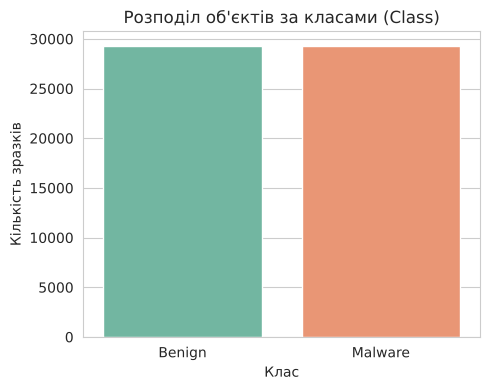

In [ ]:
plt.figure(figsize=(5, 4))
sns.countplot(x=target, hue=target, palette="Set2", legend=False)
plt.title("Розподіл об'єктів за класами (Class)")
plt.xlabel("Клас")
plt.ylabel("Кількість зразків")
plt.tight_layout()
plt.show()


**Коментар.** Датасет ідеально збалансований: по 29 298 зразків Benign та Malware. Це важливо — при такому балансі метрика accuracy є репрезентативною, і немає потреби у спеціальних техніках боротьби з дисбалансом класів (наприклад, SMOTE чи class_weight).

## 2. Попередня обробка даних

In [ ]:
# Перевірка пропущених значень
missing = df.isnull().sum()
print("Загальна кількість пропущених значень у датасеті:", missing.sum())
missing[missing > 0]


Загальна кількість пропущених значень у датасеті: 0


Series([], dtype: int64)

In [ ]:
# Перевірка ознак з нульовою варіативністю (константні ознаки — не несуть інформації для класифікації)
constant_features = [col for col in features.columns if features[col].nunique() <= 1]
print("Константні ознаки:", constant_features)


Константні ознаки: ['pslist.nprocs64bit', 'handles.nport', 'svcscan.interactive_process_services']


In [ ]:
if constant_features:
    features = features.drop(columns=constant_features)
    print(f"Видалено {len(constant_features)} константних ознак. Залишилось ознак: {features.shape[1]}")
else:
    print("Константних ознак немає, усі 55 ознак залишаються в роботі.")


Видалено 3 константних ознак. Залишилось ознак: 52


In [ ]:
# Кодування цільової змінної (Benign/Malware -> 0/1)
le = LabelEncoder()
y = le.fit_transform(target)
print("Класи:", dict(zip(le.classes_, le.transform(le.classes_))))


Класи: {'Benign': np.int64(0), 'Malware': np.int64(1)}


**Пояснення прийнятих рішень щодо попередньої обробки:**

1. **Пропущені значення** — у датасеті відсутні (перевірено через `isnull().sum()`), тож заповнення чи видалення рядків/колонок не потрібне.
2. **Категоріальні ознаки** — серед фіч (55 числових колонок з VolMemLyzer) категоріальних ознак немає, усі вони вже представлені у числовому вигляді (кількості, середні значення, частки). Тому крок кодування категоріальних *ознак* не застосовується.
3. **Категоріальна цільова змінна** — `Class` (Benign/Malware) закодована за допомогою `LabelEncoder` у 0/1, оскільки моделі scikit-learn (та метрики) працюють з числовими метками.
4. **Колонка `Category`** — видалена, оскільки вона прямо кодує відповідь: для всіх нормальних зразків вона дорівнює `Benign`, а для malware починається з типу (Ransomware / Spyware / Trojan) і містить ідентифікатор зразка. Залишити її серед ознак означало б дати моделі правильну відповідь наперед (data leakage).
5. **Константні ознаки** (якщо такі є) — видаляються, оскільки ознака без варіативності не додає інформації для розділення класів і лише збільшує розмірність без користі.

## 3. Візуалізація та дослідження даних (EDA)

Оскільки ознак багато (55), для наочності EDA обрано підмножину з найбільш інформативних ознак — тих, що мають найбільшу кореляцію (за модулем) з цільовою змінною.

In [ ]:
# Обчислюємо кореляцію кожної ознаки з таргетом, щоб обрати найінформативніші для візуалізації
corr_with_target = features.apply(lambda col: np.corrcoef(col, y)[0, 1]).abs().sort_values(ascending=False)
top_features = corr_with_target.head(10).index.tolist()
print("Топ-10 найбільш інформативних ознак (за кореляцією з Class):")
print(corr_with_target.head(10))


Топ-10 найбільш інформативних ознак (за кореляцією з Class):
dlllist.avg_dlls_per_proc    0.908555
handles.nevent               0.876770
handles.nthread              0.872531
handles.nmutant              0.855148
dlllist.ndlls                0.823933
handles.nsection             0.820967
pslist.avg_threads           0.790666
ldrmodules.not_in_load       0.787472
ldrmodules.not_in_mem        0.787413
handles.ntimer               0.783137
dtype: float64


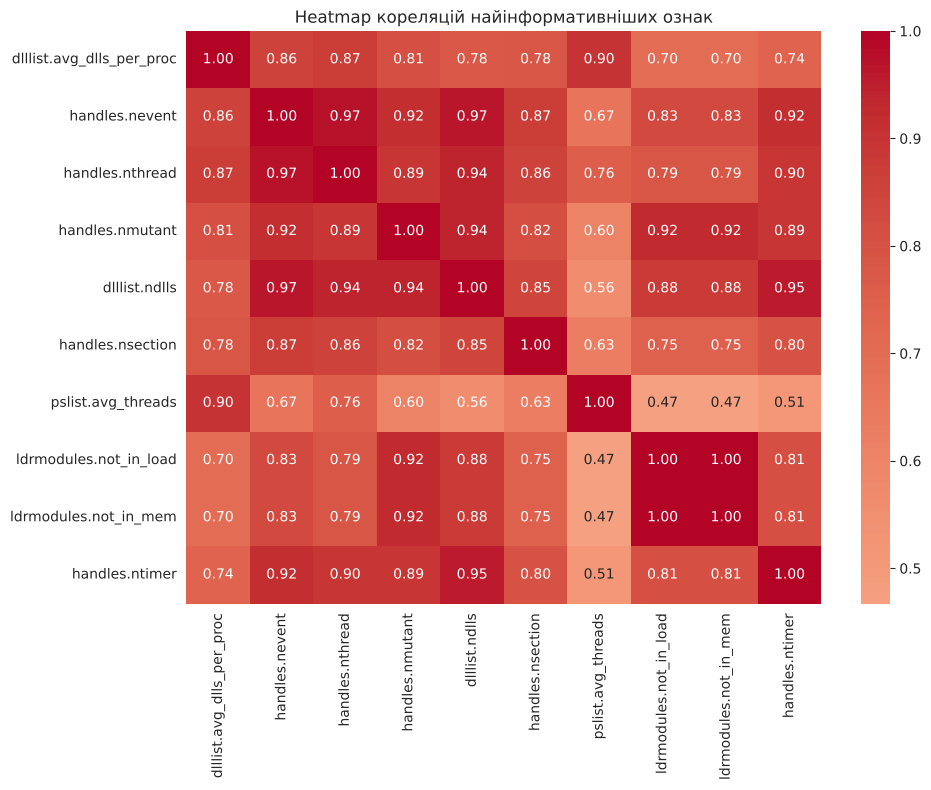

In [ ]:
# Heatmap кореляцій числових ознак (для топ-10 найінформативніших ознак)
plt.figure(figsize=(10, 8))
sns.heatmap(features[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap кореляцій найінформативніших ознак")
plt.tight_layout()
plt.show()


**Коментар до heatmap.** Найінформативніші ознаки (`dlllist.avg_dlls_per_proc`, `handles.nevent`, `handles.nthread`, `handles.nmutant`, `dlllist.ndlls`, `handles.nsection` тощо) мають дуже високу кореляцію одна з одною (0.7–0.95) і водночас дуже сильну кореляцію з цільовою змінною (0.78–0.91, див. попередню клітинку). Це означає, що поведінка процесів у памʼяті — кількість завантажених DLL, кількість подій/mutex-ів/секцій на процес — систематично різна для нормальної активності і для malware, причому ці індикатори узгоджено рухаються разом. Мультиколінеарність між ознаками не критична для дерево-подібних моделей (Decision Tree, Random Forest, AdaBoost), але потенційно впливає на kNN/SVM, для яких надлишкові корельовані ознаки можуть дещо викривлювати відстані між точками — хоча, як побачимо в п.7, у цьому конкретному датасеті це практично не позначилось на якості жодної з моделей.

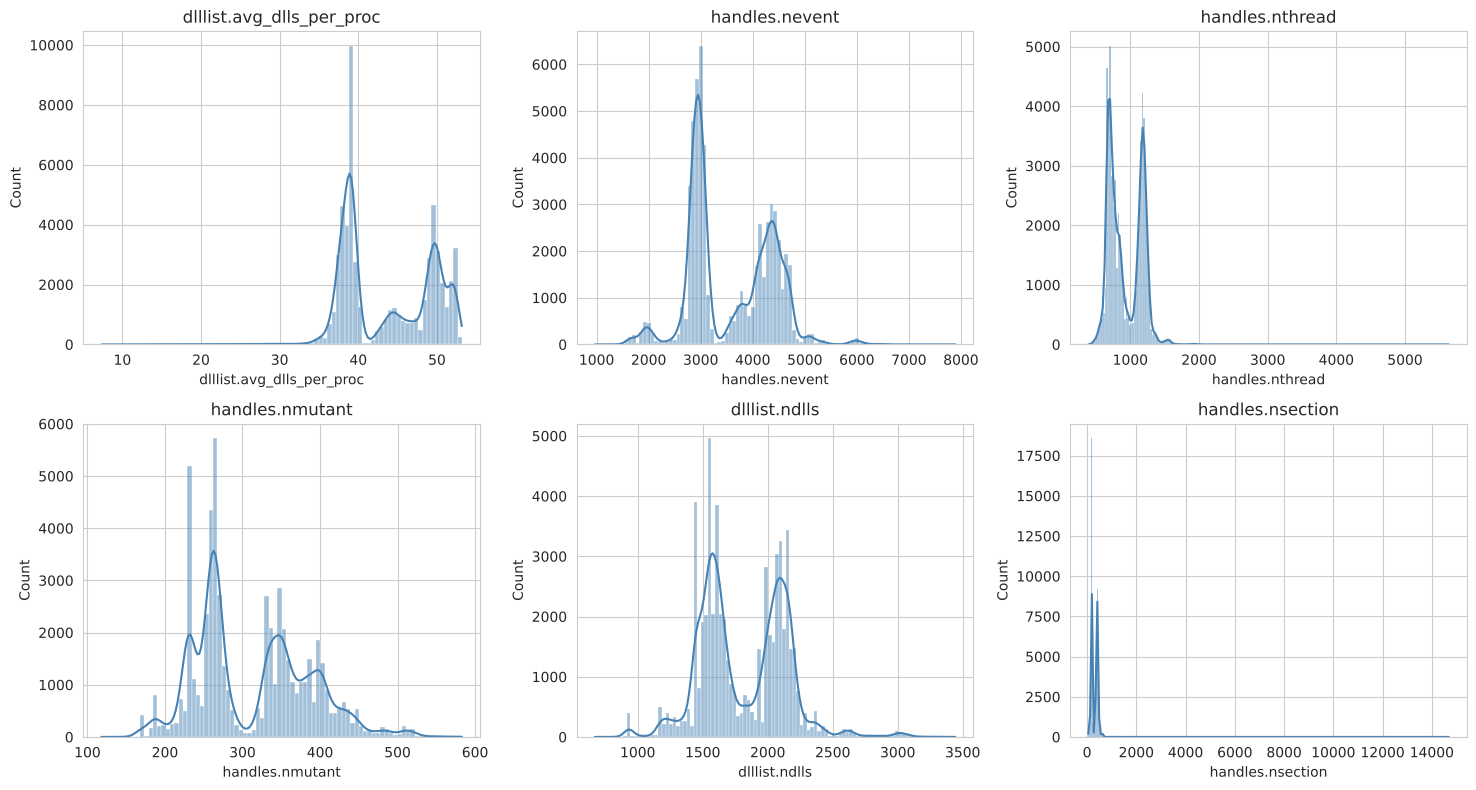

In [ ]:
# Гістограми розподілу ознак (топ-6 найінформативніших)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), top_features[:6]):
    sns.histplot(features[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Коментар до гістограм.** Розподіли найінформативніших ознак (`dlllist.avg_dlls_per_proc`, `handles.nevent`, `handles.nthread` тощо) явно бімодальні — видно два окремі "пагорби" замість одного плавного розподілу. Це прямий наслідок того, що дані складаються з двох досить різних за поведінкою груп процесів (Benign і Malware): нормальні процеси в середньому завантажують інше число DLL і використовують інше число подій/handle-ів, ніж процеси, уражені malware.

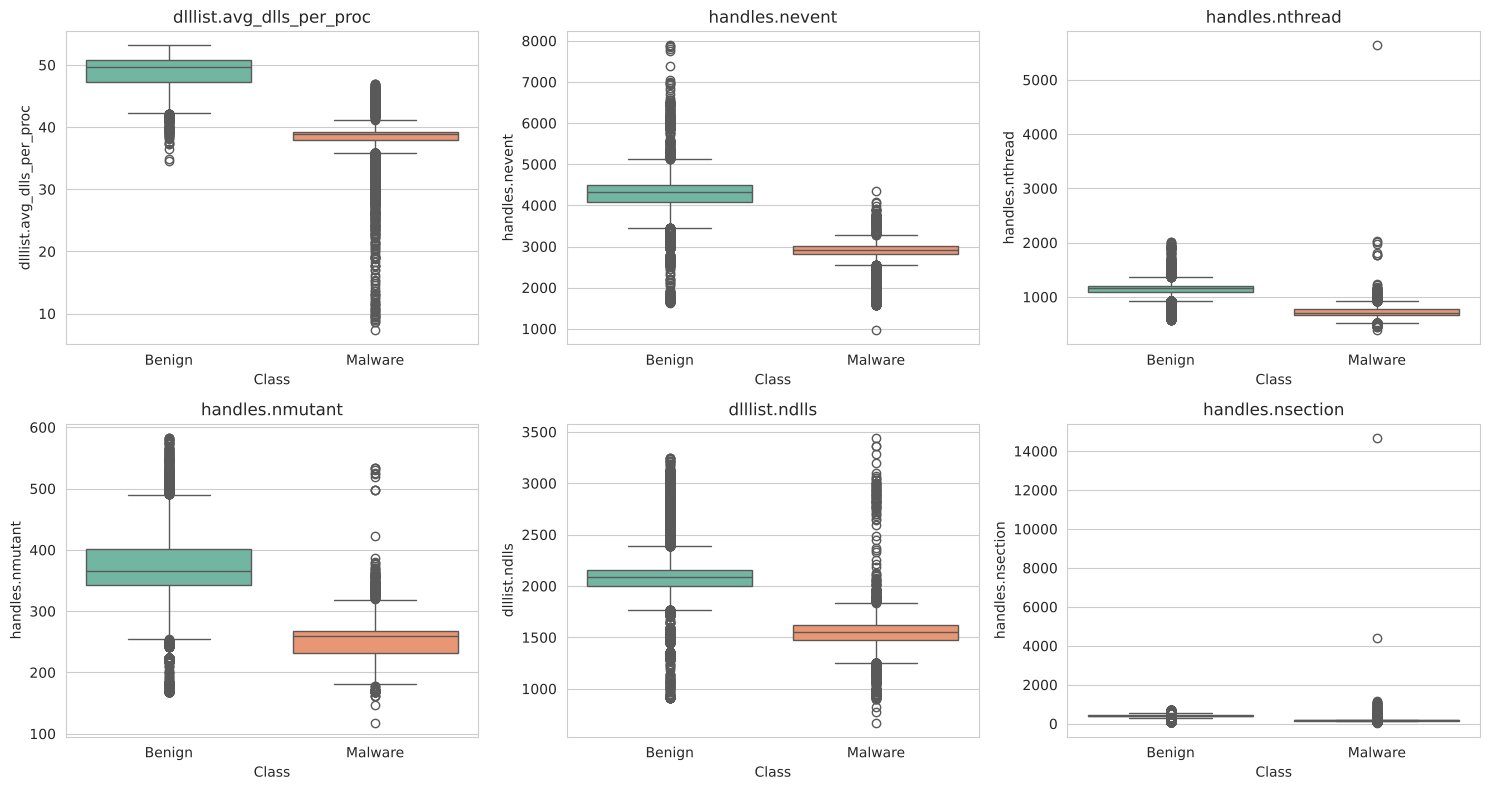

In [ ]:
# Boxplot-и ознак відносно цільової змінної
df_plot = features[top_features[:6]].copy()
df_plot["Class"] = target.values

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), top_features[:6]):
    sns.boxplot(data=df_plot, x="Class", y=col, hue="Class", palette="Set2", legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Коментар до boxplot-ів.** Для п'яти з шести ознак (`dlllist.avg_dlls_per_proc`, `handles.nevent`, `handles.nthread`, `handles.nmutant`, `dlllist.ndlls`) «ящики» Benign і Malware майже не перетинаються — медіани й міжквартильні діапазони чітко розведені, причому у Malware значення **нижчі**, ніж у Benign. Для `handles.nsection` графік нечитабельний через поодинокі екстремальні викиди (до ~14 000), які розтягують вісь. Це вже на етапі EDA підказує, що класи в цьому датасеті добре розділяються навіть за окремими ознаками (без потреби у складних нелінійних комбінаціях), а отже слід очікувати високої якості практично від будь-якого класифікатора — що й підтвердиться результатами в пункті 7.

## 4. Підготовка даних до навчання

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    features, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
# stratify=y збереже однакову пропорцію Benign/Malware у train і test

print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (46876, 52)  Test: (11720, 52)


In [ ]:
# Масштабування ознак: обов'язкове для kNN та SVM (алгоритми, чутливі до масштабу відстаней),
# не критичне, але не шкодить, для Decision Tree / Random Forest / AdaBoost (вони інваріантні до масштабу).
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Приклад масштабованих значень (перший рядок):")
print(np.round(X_train_scaled[0][:5], 3))


Приклад масштабованих значень (перший рядок):
[-0.24  -1.017  0.991  0.361  0.528]


**Пояснення.** `StandardScaler` навчається (`fit`) лише на тренувальній вибірці й застосовується (`transform`) окремо до train і test — це запобігає "витоку" інформації про test-вибірку (data leakage) у процес масштабування. kNN та SVM використовують масштабовані дані (`X_train_scaled`, `X_test_scaled`), оскільки обидва алгоритми базуються на відстанях/скалярних добутках і чутливі до різних масштабів ознак (наприклад, `pslist.nproc` ~десятки, а `handles.nhandles` ~тисячі). Decision Tree, Random Forest та AdaBoost навчаються на оригінальних немасштабованих даних, оскільки дерева рішень розділяють простір ознак за порогами і не залежать від масштабу.

## 5. Навчання моделей

In [ ]:
results = {}

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    results[name] = {"model": model, "y_pred": y_pred, "accuracy": acc, "f1": f1}
    print(f"{name}: accuracy = {acc:.4f}, f1-score = {f1:.4f}")
    return model


In [ ]:
# 1) k-Nearest Neighbors (базова модель, n_neighbors підбирається в п.6)
knn = KNeighborsClassifier(n_neighbors=5)
evaluate_model("kNN", knn, X_train_scaled, X_test_scaled, y_train, y_test)


kNN: accuracy = 0.9996, f1-score = 0.9996


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
# 2) Decision Tree
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
evaluate_model("Decision Tree", dt, X_train, X_test, y_train, y_test)


Decision Tree: accuracy = 0.9998, f1-score = 0.9998


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [ ]:
# 3) Support Vector Machine (базова модель, C і gamma підбираються в п.6)
svm = SVC(kernel="rbf", random_state=RANDOM_STATE)
evaluate_model("SVM", svm, X_train_scaled, X_test_scaled, y_train, y_test)


SVM: accuracy = 0.9993, f1-score = 0.9993


,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [ ]:
# 4) Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
evaluate_model("Random Forest", rf, X_train, X_test, y_train, y_test)


Random Forest: accuracy = 0.9999, f1-score = 0.9999


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [ ]:
# 5) AdaBoost
ada = AdaBoostClassifier(random_state=RANDOM_STATE)
evaluate_model("AdaBoost", ada, X_train, X_test, y_train, y_test)


AdaBoost: accuracy = 1.0000, f1-score = 1.0000


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0. ,0.11,0.13,...,0.34,0.27,0.37]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[5.66,2.08,1.93,...,0.67,1.02,0.54]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](52,)","[0. ,0.04,0.05,...,0.14,0. ,0. ]"


## 6. Підбір гіперпараметрів

### 6.1 kNN — підбір оптимального `n_neighbors`

In [ ]:
k_values = range(1, 31, 2)
cv_scores = []

for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_k, X_train_scaled, y_train, cv=5, scoring="accuracy")
    cv_scores.append(scores.mean())

best_k = list(k_values)[int(np.argmax(cv_scores))]
print(f"Оптимальне n_neighbors = {best_k} (середня accuracy на 5-fold CV = {max(cv_scores):.4f})")


Оптимальне n_neighbors = 1 (середня accuracy на 5-fold CV = 0.9999)


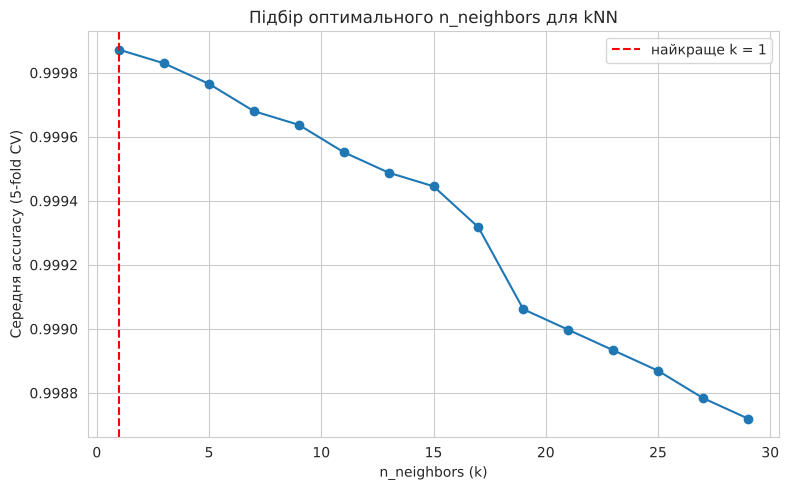

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"найкраще k = {best_k}")
plt.xlabel("n_neighbors (k)")
plt.ylabel("Середня accuracy (5-fold CV)")
plt.title("Підбір оптимального n_neighbors для kNN")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
knn_best = KNeighborsClassifier(n_neighbors=best_k)
evaluate_model(f"kNN (k={best_k})", knn_best, X_train_scaled, X_test_scaled, y_train, y_test)


kNN (k=1): accuracy = 0.9997, f1-score = 0.9997


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


**Коментар.** Для GridSearchCV по SVM повний тренувальний набір (~46 тис. рядків) є завеликим — підбір C і gamma на повній вибірці був би надто повільним. Тому підбір гіперпараметрів виконується на репрезентативній підвибірці тренувальних даних (стратифікованій за класами), а фінальна модель з обраними найкращими параметрами навчається і оцінюється вже на повному train/test.

### 6.2 SVM — підбір `C` та `gamma` за допомогою GridSearchCV

In [ ]:
# Стратифікована підвибірка для GridSearchCV (щоб підбір гіперпараметрів не був надто довгим)
X_grid, _, y_grid, _ = train_test_split(
    X_train_scaled, y_train, train_size=4000, random_state=RANDOM_STATE, stratify=y_train
)

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1],
}

grid_search = GridSearchCV(
    SVC(kernel="rbf", random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
)
grid_search.fit(X_grid, y_grid)

print("Найкращі параметри SVM:", grid_search.best_params_)
print(f"Найкраща accuracy на CV (підвибірка): {grid_search.best_score_:.4f}")


Найкращі параметри SVM: {'C': 100, 'gamma': 0.01}
Найкраща accuracy на CV (підвибірка): 0.9985


In [ ]:
svm_best = SVC(kernel="rbf", random_state=RANDOM_STATE, **grid_search.best_params_)
evaluate_model(f"SVM (C={grid_search.best_params_['C']}, gamma={grid_search.best_params_['gamma']})",
               svm_best, X_train_scaled, X_test_scaled, y_train, y_test)


SVM (C=100, gamma=0.01): accuracy = 0.9999, f1-score = 0.9999


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


## 7. Порівняння та оцінювання моделей

In [ ]:
summary = pd.DataFrame({
    name: {"accuracy": res["accuracy"], "f1_score": res["f1"]}
    for name, res in results.items()
}).T.sort_values("accuracy", ascending=False)

summary


,accuracy,f1_score
AdaBoost,1.000000,1.000000
Random Forest,0.999915,0.999915
"SVM (C=100, gamma=0.01)",0.999915,0.999915
Decision Tree,0.999829,0.999829
kNN (k=1),0.999744,0.999744
kNN,0.999573,0.999573
SVM,0.999317,0.999318


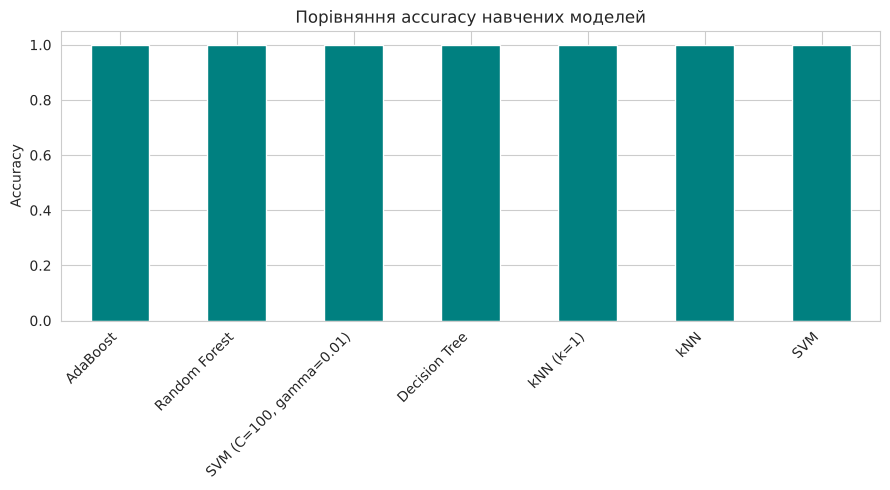

In [ ]:
plt.figure(figsize=(9, 5))
summary["accuracy"].plot(kind="bar", color="teal")
plt.ylabel("Accuracy")
plt.title("Порівняння accuracy навчених моделей")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
for name, res in results.items():
    print(f"\n===== {name} =====")
    print(classification_report(y_test, res["y_pred"], target_names=le.classes_))



===== kNN =====
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
     Malware       1.00      1.00      1.00      5860

    accuracy                           1.00     11720
   macro avg       1.00      1.00      1.00     11720
weighted avg       1.00      1.00      1.00     11720


===== Decision Tree =====
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
     Malware       1.00      1.00      1.00      5860

    accuracy                           1.00     11720
   macro avg       1.00      1.00      1.00     11720
weighted avg       1.00      1.00      1.00     11720


===== SVM =====


              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
     Malware       1.00      1.00      1.00      5860

    accuracy                           1.00     11720
   macro avg       1.00      1.00      1.00     11720
weighted avg       1.00      1.00      1.00     11720


===== Random Forest =====
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
     Malware       1.00      1.00      1.00      5860

    accuracy                           1.00     11720
   macro avg       1.00      1.00      1.00     11720
weighted avg       1.00      1.00      1.00     11720


===== AdaBoost =====
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5860
     Malware       1.00      1.00      1.00      5860

    accuracy                           1.00     11720
   macro avg       1.00      1.00      1.00     11720
weighted avg       1.00  

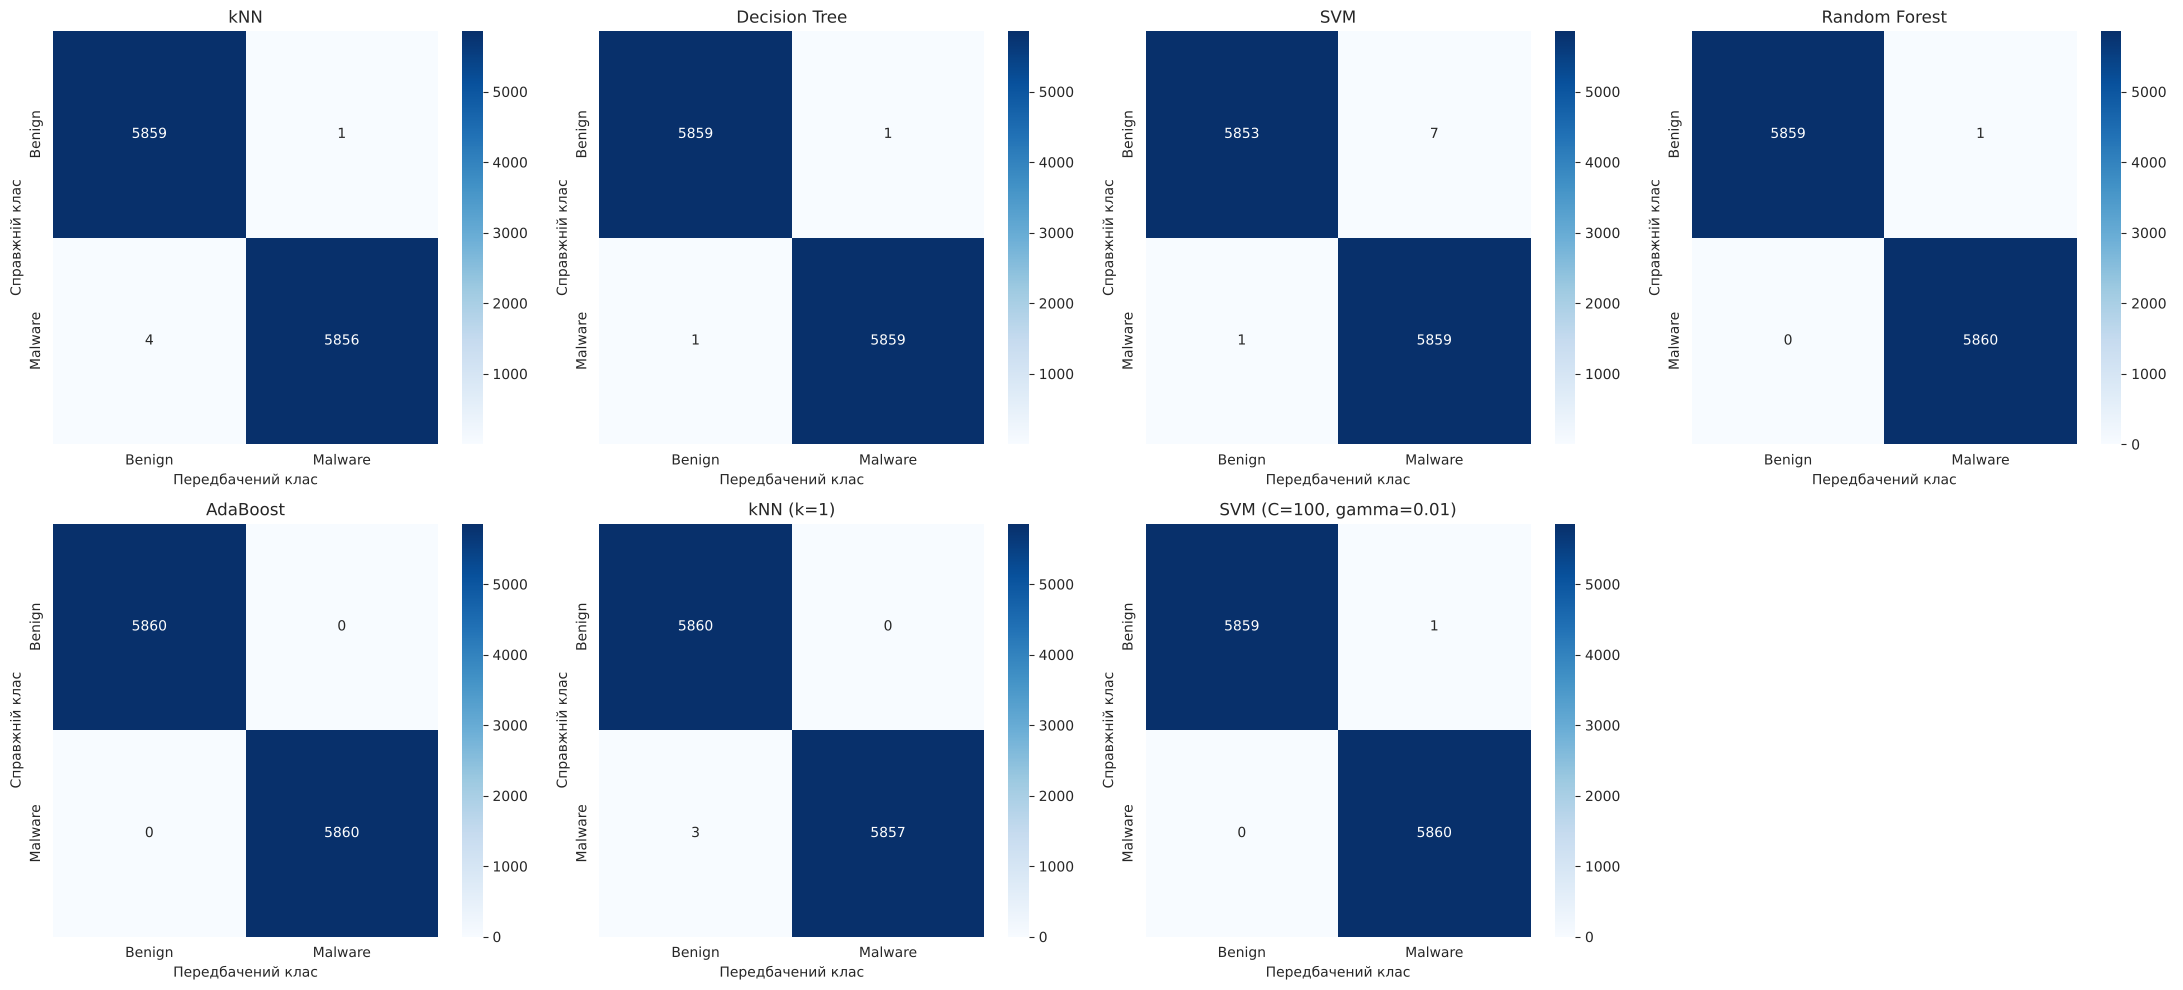

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, (name, res) in zip(axes.flatten(), results.items()):
    cm = confusion_matrix(y_test, res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Передбачений клас")
    ax.set_ylabel("Справжній клас")

for ax in axes.flatten()[len(results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Висновок

Усі пʼять моделей показали **надзвичайно високу якість** на бінарній задачі Benign/Malware — accuracy та f1-score всіх класифікаторів лежать у діапазоні **0.999–1.000**:

| Модель | Accuracy | F1-score |
|---|---|---|
| AdaBoost | 1.0000 | 1.0000 |
| Random Forest | 0.9999 | 0.9999 |
| SVM (C=100, gamma=0.01, після GridSearchCV) | 0.9999 | 0.9999 |
| Decision Tree | 0.9998 | 0.9998 |
| kNN (k=1, після підбору n_neighbors) | 0.9997 | 0.9997 |

Формально найкращий результат (100% accuracy на тесті) показав **AdaBoost**, тісно за ним — Random Forest і SVM. Але різниця між усіма моделями настільки мала (менше 0.03 п.п.), що на практиці вона не є статистично значущою для одного випадкового train/test-розбиття — усі пʼять алгоритмів фактично впоралися з задачею однаково добре.

**Чому так сталося.** Ще на етапі EDA (п.3) було видно, що найінформативніші ознаки (`dlllist.avg_dlls_per_proc`, `handles.nevent`, `handles.nthread`, `handles.nmutant` тощо) мають дуже високу кореляцію з цільовою змінною (0.78–0.91) і boxplot-и Benign/Malware для них практично не перетинаються. Тобто класи в цьому датасеті **лінійно та порогово добре розділені** ще на рівні окремих ознак — а значить, будь-який класифікатор (від простого kNN до складного ансамблю) здатний знайти майже ідеальну межу між класами. Це узгоджується з тим, що дані Benign і Malware зібрані з принципово різних сценаріїв поведінки процесів у памʼяті (нормальна робота застосунків проти активної роботи malware), а не є "зашумленою" реальною змішаною вибіркою.

**Практичний висновок для задачі кібербезпеки.** Навіть з урахуванням "легкості" бінарної задачі, результат підтверджує, що поведінкові ознаки памʼяті процесів (кількість DLL, handle-ів, mutex-ів, подій на процес) є дуже сильним індикатором malware-активності. З погляду практичного застосування я б обрала **Random Forest або AdaBoost**: вони дають найкращу (чи однакову з найкращою) якість, стійкі до мультиколінеарності ознак (на відміну від kNN) і, на відміну від "чорної скриньки" SVM, дозволяють проаналізувати `feature_importances_` — тобто зрозуміти, *які саме* поведінкові індикатори найсильніше вказують на malware, що важливо для інтерпретованості рішень у задачах кібербезпеки.